## Template matching algorithm

In [1]:
import cv2 as cv
import numpy as np
from pathlib import Path
import math
import torch
import torchvision.transforms.functional as TF
import torch.nn.functional as F
from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

Load template matching files (if it returns an error, use full path):

In [ ]:
directory = Path('/Team_AIR/Vision/Numbers')
files = sorted([f for f in directory.iterdir() if f.is_file() and f.suffix.lower() == ".jpg"])

In [3]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)

print(device)

mps


Load CNN:

In [ ]:
exported_program = torch.export.load("Team_AIR/Vision/team_air_gcp_localization_protoype.pt2")
cnn = exported_program.module()

The current template matching algorithm, where $img$ is the 94x80 grayscale image after processing algorithm. Ouputs $num$, the classification, and $conf$, the confidence value, as $(num, conf)$. The activation function (a variation of $\frac{1}{1+e^{-t*x}}$) is arrived at by eye-balling the graph. Essentially, we double to verticle scale so $0 < f(+x) < 1$ and horizontally scale (with temperature $t$) so that $f(0.15) \approx 0.9$, where $0.15$ is from online forums. This is multiplied by a similar function for the for the actual conf of the algorithm, just that we make sure $f(+x) > 0$ so that the $diff$ is the main criterion. We use zero-mean normalized correlation coefficient, which is not available on NVIDIA VPI.

In [8]:
def conf_func(diff, val):
    return ((2 / (1 + math.exp(-20*diff))) - 1) * ((2 / (1 + math.exp(-4.7*val))) - 1)

# Run template matching
def template_match(img):
    # In the final file, we should load the files into cuda before run
    l = []
    for entry in files:
        template = cv.imread(entry)[:, :, 1]
        res = cv.matchTemplate(img, template, cv.TM_CCOEFF_NORMED)
        l.append(cv.minMaxLoc(res)[1])

    arr = sorted(l)
    # num, conf
    # Included arr[-1] to track actual confidence value
    return np.argmax(np.array(l)), conf_func(arr[-1] - arr[-2], arr[-1]), arr[-1]

Run through the folders in 'Vision/Template Matching Data'. I merged all the folders into a single folder for classification. We check if $conf > 0.85$ (as the functions were calculated so ideal $x$ yields $f(x) \approx 0.9$, and $0.9^2 = 0.81$, and I added a bit of buffer). If it is lower, we delegate to CNN.

In [21]:
incorrect_images = [] # In (Path, pred, actual, conf, who)

# We run inference on all images
total_cnn_pred = []
total_cnn_conf = [] 

y_true = [] # Actual Value
y_pred = [] # Pred

# The following are only on images of the right dimensions
valid_y_true = []  # Actual values for correctly sized images
template_pred = [] # Tem pred
template_conf = [] # Tem conf
cnn_pred = [] # CNN pred
cnn_conf = [] # CNN conf

true_template_pred = []
true_template_conf = []

cnn_used = [] # How many times the CNN was used per i
size_mismatches = [] # Wrong dimesnions per i

total_images = 0
for i in range(10):
    # Classification: i
    curr_dir = Path(f'/Users/abhiroopsahu/Documents/Team_AIR/Vision/Template Matching Data/{i}')
    cMod = [] # Confidence of CNN
    cAlg = [] # Confidence of Template Matching
    n = [] # Number predicted
    k = [] # Actual confidence of Template Matching
    r = [] # Ratio of CNN usage
    size_mismatch = 0
    print(25*"*", f"Classification for {i}", 25*"*")
    for entry in curr_dir.iterdir():
        if entry.is_file() and entry.suffix.lower() == ".png":
            # The grayscale image already is just the greens
            img = cv.imread(entry)[74:168, 168:248, 1]
            total_images += 1

            # Template matching
            # Guaranteed images of right dimensions
            t_num, t_conf, actual = template_match(img)

            # CNN
            num_tensor = TF.to_tensor(img).unsqueeze(0).to(device)
           
            c_num = c_conf = -1
            with torch.inference_mode():
                cnn_output = cnn(num_tensor)
                probabilities = torch.softmax(cnn_output / 1.25, dim=1)

                c_num = torch.argmax(probabilities, dim=1).item()
                c_conf = torch.max(probabilities).item()
                cMod.append(c_conf)

            if (c_num == -1 or c_conf == -1):
                # Shouldn't be happening
                raise ValueError            
            total_cnn_conf.append(c_conf)
            total_cnn_pred.append(c_num)

            # Hybrid selection
            # Initially
            num = t_num
            final_conf = t_conf
            cnn_count = 0

            if t_conf < 0.85 and c_conf > t_conf:
                cnn_count = 1
                num = c_num
                final_conf = c_conf
            else:
                valid_y_true.append(i)
                true_template_conf.append(t_conf)
                true_template_pred.append(t_num)
                cAlg.append(t_conf)

                

            # Record everything
            y_true.append(i)
            y_pred.append(num)

            template_pred.append(t_num)
            template_conf.append(t_conf)

            cnn_pred.append(c_num)
            cnn_conf.append(c_conf)

            n.append(num)
            k.append(actual)
            r.append(cnn_count)

            if (num != i):
                # (Path, pred, actual, conf, who)
                who = "CNN" if c_conf == final_conf else "Tem"
                incorrect_images.append((f"/Users/abhiroopsahu/Documents/Team_AIR/Vision/Template Matching Data/{i}/{entry.name}", num, i, final_conf, who))
                print(60*"-")
                print(f"Misclassified: {entry.name}, Predicted: {num}, Confidence: {final_conf}")
                print(60*"-", "\n")

    size_mismatches.append(size_mismatch)
    cnn_used.append((sum(r) - size_mismatch, len(r) - size_mismatch)) # (Number of times CNN was used, Number of images for class i)
    print(f"Accuracy for {i}: {n.count(i)/len(n)}")
    print(f"Average CNN Confidence for {i}: {sum(cMod)/len(cMod)}" if len(cMod) > 0 else "CNN model did not run")
    print(f"Average Template Matching Confidence for {i}: {sum(cAlg)/len(cAlg)}" if len(cAlg) > 0 else "Template matching algo did not run")
    print(f"Actual Template Matching Confidence: {sum(k)/len(k)}")
    print(f"Ratio of CNN usage for {i}: {sum(r)}:{len(r)}, of which {size_mismatch} were due to size mismatch")
    print(f"Actual Ratio of CNN usage for {i}: {sum(r) - size_mismatch}:{len(r) - size_mismatch} = {(sum(r) - size_mismatch) / (len(r) - size_mismatch)}\n\n")

print(f"\nTotal number of images processed: {total_images}\nNumber of images incorrectly classified: {len(incorrect_images)}")

************************* Classification for 0 *************************
Accuracy for 0: 1.0
Average CNN Confidence for 0: 0.9922447435220881
Average Template Matching Confidence for 0: 0.945914408883653
Actual Template Matching Confidence: 0.6168127009017983
Ratio of CNN usage for 0: 152:199, of which 0 were due to size mismatch
Actual Ratio of CNN usage for 0: 152:199 = 0.7638190954773869


************************* Classification for 1 *************************
------------------------------------------------------------
Misclassified: 1_img1867_a6082.png, Predicted: 7, Confidence: 0.45961490273475647
------------------------------------------------------------ 

Accuracy for 1: 0.9952830188679245
Average CNN Confidence for 1: 0.967411644616217
Average Template Matching Confidence for 1: 0.936839347885761
Actual Template Matching Confidence: 0.6304402265627429
Ratio of CNN usage for 1: 109:212, of which 0 were due to size mismatch
Actual Ratio of CNN usage for 1: 109:212 = 0.5141509

### Results in Graphs

All the images incorrectly classified (note, the last one is in the wrong category):

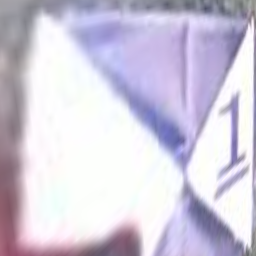

Prediction: 7
Actual: 1
Confidence: 0.45961490273475647
Classifier: CNN


In [22]:
for path, pred, actual, conf, who in incorrect_images:
    display(Image(filename=path))
    print(f"Prediction: {pred}")
    print(f"Actual: {actual}")
    print(f"Confidence: {conf}")
    print(f"Classifier: {who}")

I asked ChatGPT to make some graphs, so enjoy ig:


OVERALL CLASSIFICATION STATISTICS
Total images: 3282
Hybrid accuracy: 99.9695%
CNN accuracy: 99.8781%
Template matching accuracy: 100.0000%

CNN usage (normal-sized images): 1028/3282 (31.32%)
Size mismatches: 0/3282


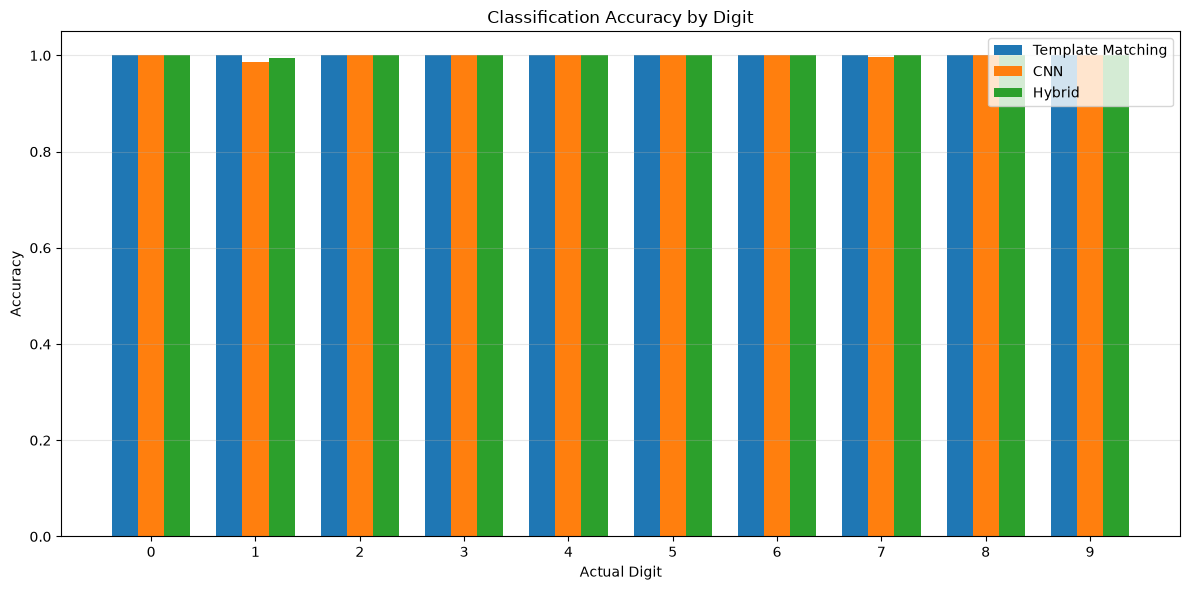

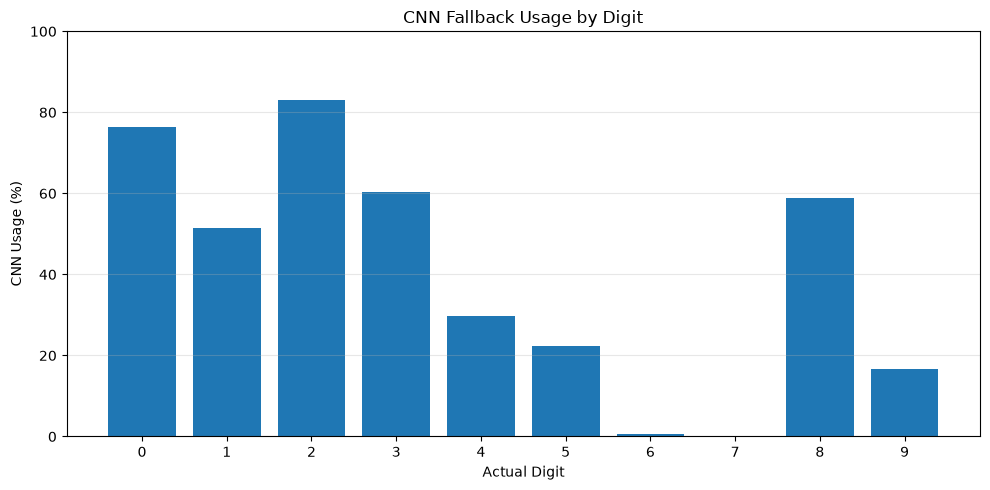

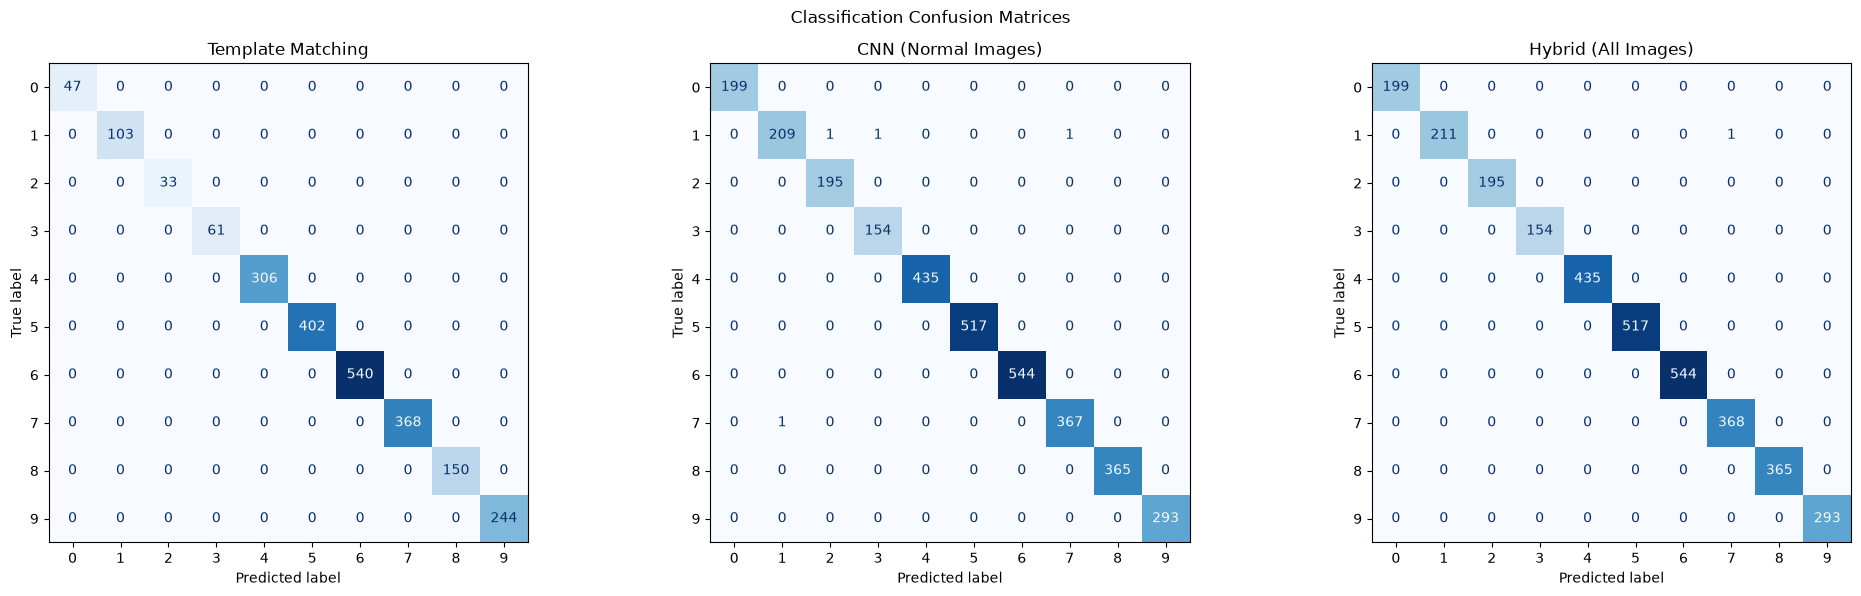

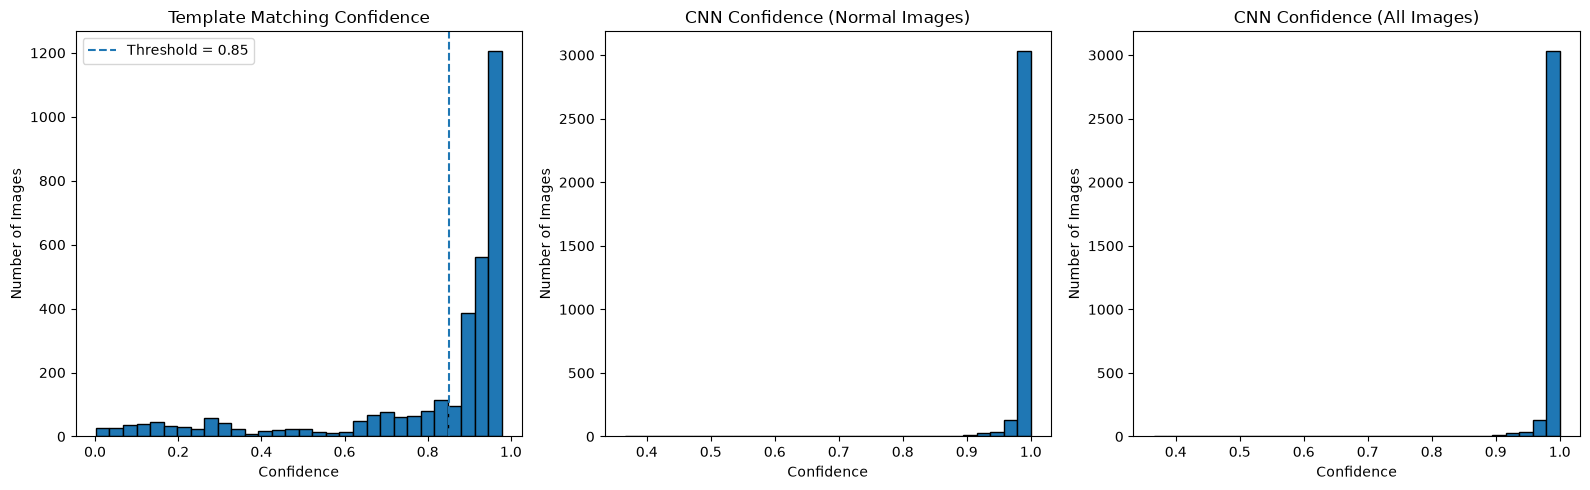

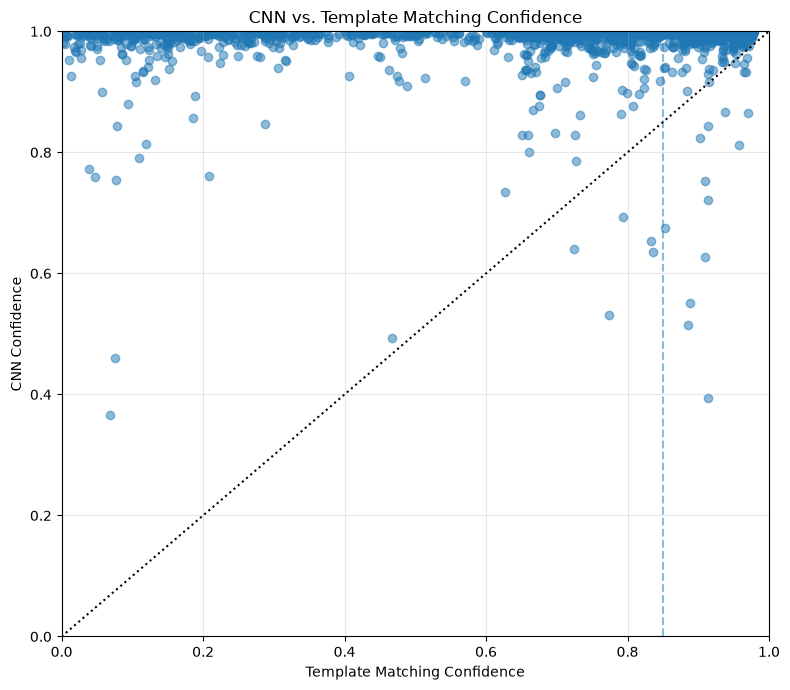

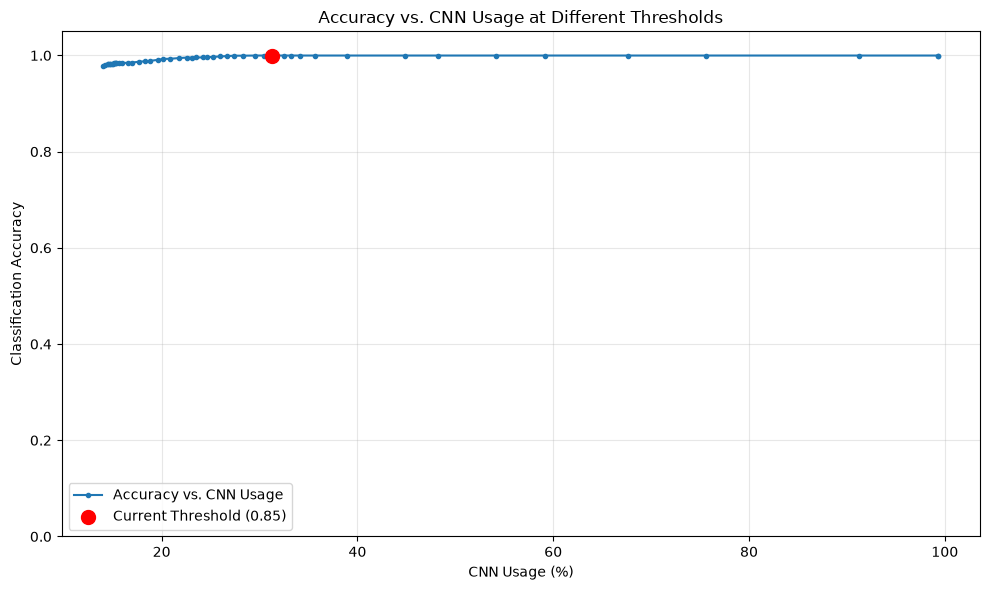


MISCLASSIFICATION SUMMARY
Hybrid: 1/3282 (0.03% incorrect)
Digit 0: 0/199 incorrect (0.00%)
Digit 1: 1/212 incorrect (0.47%)
Digit 2: 0/195 incorrect (0.00%)
Digit 3: 0/154 incorrect (0.00%)
Digit 4: 0/435 incorrect (0.00%)
Digit 5: 0/517 incorrect (0.00%)
Digit 6: 0/544 incorrect (0.00%)
Digit 7: 0/368 incorrect (0.00%)
Digit 8: 0/365 incorrect (0.00%)
Digit 9: 0/293 incorrect (0.00%)


In [23]:
digits = np.arange(10)

def statistics():
    # ==================================================
    # 1. OVERALL STATISTICS
    # ==================================================

    print("\n" + 60 * "=")
    print("OVERALL CLASSIFICATION STATISTICS")
    print(60 * "=")

    hybrid_accuracy = accuracy_score(y_true, y_pred)
    cnn_accuracy = accuracy_score(y_true, total_cnn_pred)

    template_accuracy = accuracy_score(
        valid_y_true, true_template_pred
    )

    print(f"Total images: {total_images}")
    print(f"Hybrid accuracy: {hybrid_accuracy:.4%}")
    print(f"CNN accuracy: {cnn_accuracy:.4%}")
    print(f"Template matching accuracy: {template_accuracy:.4%}")

    total_normal = sum(x[1] for x in cnn_used)
    total_used = sum(x[0] for x in cnn_used)

    print(f"\nCNN usage (normal-sized images): "
        f"{total_used}/{total_normal} "
        f"({total_used / total_normal:.2%})")

    print(f"Size mismatches: {sum(size_mismatches)}/{total_images}")

    # ==================================================
    # 2. ACCURACY BY DIGIT
    # ==================================================

    hybrid_acc = []
    cnn_acc = []
    template_acc = []

    for i in digits:

        # All images
        indices = [j for j, t in enumerate(y_true) if t == i]

        hybrid_acc.append(
            np.mean([y_pred[j] == i for j in indices])
        )

        cnn_acc.append(
            np.mean([total_cnn_pred[j] == i for j in indices])
        )

        # Correctly sized images only
        indices = [
            j for j, t in enumerate(valid_y_true) if t == i
        ]

        template_acc.append(
            np.mean([true_template_pred[j] == i for j in indices])
        )

    x = np.arange(10)
    width = 0.25

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.bar(x - width, template_acc, width, label="Template Matching")
    ax.bar(x, cnn_acc, width, label="CNN")
    ax.bar(x + width, hybrid_acc, width, label="Hybrid")

    ax.set_xlabel("Actual Digit")
    ax.set_ylabel("Accuracy")
    ax.set_title("Classification Accuracy by Digit")
    ax.set_xticks(x)
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    # ==================================================
    # 3. CNN USAGE BY DIGIT
    # ==================================================

    usage = [
        used / total if total > 0 else 0
        for used, total in cnn_used
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar(digits, np.array(usage) * 100)

    ax.set_xlabel("Actual Digit")
    ax.set_ylabel("CNN Usage (%)")
    ax.set_title("CNN Fallback Usage by Digit")
    ax.set_xticks(digits)
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    # ==================================================
    # 4. CONFUSION MATRICES
    # ==================================================

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    matrices = [
        (valid_y_true, true_template_pred, "Template Matching"),
        (y_true, cnn_pred, "CNN (Normal Images)"),
        (y_true, y_pred, "Hybrid (All Images)")
    ]

    for ax, (truth, predictions, title) in zip(axes, matrices):

        cm = confusion_matrix(
            truth,
            predictions,
            labels=digits
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=digits
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            colorbar=False
        )

        ax.set_title(title)

    plt.suptitle("Classification Confusion Matrices")
    plt.tight_layout()
    plt.show()

    # ==================================================
    # 5. CONFIDENCE DISTRIBUTIONS
    # ==================================================

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].hist(
        template_conf,
        bins=30,
        edgecolor="black"
    )

    axes[0].axvline(
        0.85,
        linestyle="--",
        label="Threshold = 0.85"
    )

    axes[0].set_title("Template Matching Confidence")
    axes[0].set_xlabel("Confidence")
    axes[0].set_ylabel("Number of Images")
    axes[0].legend()

    axes[1].hist(
        cnn_conf,
        bins=30,
        edgecolor="black"
    )

    axes[1].set_title("CNN Confidence (Normal Images)")
    axes[1].set_xlabel("Confidence")
    axes[1].set_ylabel("Number of Images")

    axes[2].hist(
        total_cnn_conf,
        bins=30,
        edgecolor="black"
    )

    axes[2].set_title("CNN Confidence (All Images)")
    axes[2].set_xlabel("Confidence")
    axes[2].set_ylabel("Number of Images")

    plt.tight_layout()
    plt.show()

    # ==================================================
    # 6. CNN VS TEMPLATE MATCHING CONFIDENCE
    # ==================================================

    fig, ax = plt.subplots(figsize=(8, 7))

    ax.scatter(
        template_conf,
        cnn_conf,
        alpha=0.5
    )

    ax.axvline(0.85, linestyle="--", alpha=0.5)
    ax.plot([0, 1], [0, 1], linestyle=":", color="black")

    ax.set_xlabel("Template Matching Confidence")
    ax.set_ylabel("CNN Confidence")
    ax.set_title("CNN vs. Template Matching Confidence")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # ==================================================
    # 7. THRESHOLD OPTIMIZATION
    # ==================================================

    thresholds = np.arange(0.50, 1.00, 0.01)

    threshold_accuracy = []
    threshold_usage = []

    for threshold in thresholds:

        predictions = []

        for t_num, t_conf, c_num, c_conf in zip(
            template_pred,
            template_conf,
            cnn_pred,
            cnn_conf
        ):

            num = t_num

            if t_conf < threshold and c_conf > t_conf:
                num = c_num

            predictions.append(num)

        threshold_accuracy.append(
            accuracy_score(y_true, predictions)
        )

        threshold_usage.append(
            np.mean([
                t_conf < threshold and c_conf > t_conf
                for t_conf, c_conf in zip(template_conf, cnn_conf)
            ])
        )

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(
        np.array(threshold_usage) * 100,
        threshold_accuracy,
        marker=".",
        label="Accuracy vs. CNN Usage"
    )

    current_index = np.argmin(np.abs(thresholds - 0.85))

    ax.scatter(
        threshold_usage[current_index] * 100,
        threshold_accuracy[current_index],
        color="red",
        s=100,
        label="Current Threshold (0.85)",
        zorder=5
    )

    ax.set_xlabel("CNN Usage (%)")
    ax.set_ylabel("Classification Accuracy")
    ax.set_title("Accuracy vs. CNN Usage at Different Thresholds")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # ==================================================
    # 8. MISCLASSIFICATION SUMMARY
    # ==================================================

    print("\n" + 60 * "=")
    print("MISCLASSIFICATION SUMMARY")
    print(60 * "=")

    print(f"Hybrid: {len(incorrect_images)}/{total_images} "
        f"({len(incorrect_images)/total_images:.2%} incorrect)")

    for i in digits:

        indices = [j for j, t in enumerate(y_true) if t == i]

        incorrect = sum(
            y_pred[j] != i for j in indices
        )

        print(
            f"Digit {i}: {incorrect}/{len(indices)} incorrect "
            f"({incorrect / len(indices):.2%})"
        )

statistics()
